# Designing a Joint Intelligence

*The Mathematics of Machine Intelligence · Chapter 25*

Share a task between a person and a machine, and test whether the pair beats the better one alone.

These pages illustrate the mathematics. Read the saved figures and calculations in order, or open [the interactive browser edition](reader.html) to change the examples. No code editing is needed. Every figure is computed from the chapter's own equations or from a disclosed simulation; a simulation is not a measurement, and the mathematics of a brain is a model.

Ask what the person alone, the machine alone and the pair each score on comparable cases, what asking the person costs, and how many cases the two disagree on. Use the routing card to compare the partners case type by case type, and the override card to say whether the person wins more than half of the disagreements. Report the whole arrangement against each partner alone, and say which numbers were estimated under the conditions of use.

<details><summary>Reproducing these calculations</summary>

The optional calculation cells use Python with NumPy and Matplotlib. All inputs, random seeds and functions are included in this file. The figures below are saved, so running these cells is optional.

</details>

In [1]:
import io
import math
import re
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown
from cycler import cycler
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 11, 'axes.titlesize': 13, 'axes.labelsize': 11, 'xtick.labelsize': 10, 'ytick.labelsize': 10, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': '#7d8588', 'axes.labelcolor': '#172a3b', 'text.color': '#172a3b', 'xtick.color': '#52606b', 'ytick.color': '#52606b', 'figure.facecolor': 'white', 'axes.facecolor': 'white', 'savefig.facecolor': 'white', 'grid.alpha': 0.2, 'lines.linewidth': 2, 'svg.fonttype': 'path', 'axes.unicode_minus': False})
plt.rcParams['axes.prop_cycle'] = cycler(color=['#136f75', '#b77518', '#334c72', '#aa4e37', '#677341'])

def clean_display_text(text):
    """Remove signed zero only after an explicitly formatted value rounds to zero."""
    return re.sub(r"(?<![\w.])-(?:0+(?:\.0*)?|\.0+)(?:[eE][+-]?\d+)?(?![\w.])", "0", text)


def display_value(value):
    """One display policy for readers, saved notebooks and skill references."""
    if hasattr(value, "item") and getattr(value, "size", 1) == 1:
        value = value.item()
    if isinstance(value, float):
        if not math.isfinite(value):
            raise ValueError("Return undefined or infinity as a labeled string, not a nonfinite JSON value")
        return "0" if value == 0 else f"{value:.6g}"
    if isinstance(value, str):
        return clean_display_text(value)
    if isinstance(value, (list, tuple)):
        opening, closing = ("(", ")") if isinstance(value, tuple) else ("[", "]")
        return opening + ", ".join(str(display_value(v)) for v in value) + closing
    if isinstance(value, dict):
        return "{" + ", ".join(str(k) + ": " + str(display_value(v)) for k, v in value.items()) + "}"
    return value


"""Chapter 25, Designing a Joint Intelligence: executable mathematics and reader-facing teaching content."""
import math
import numpy as np
import matplotlib.pyplot as plt
NAVY = '#17324d'
TEAL = '#147d86'
GOLD = '#d8a23c'
DARK_GOLD = '#8a5a0f'
TERRA = '#bf6045'
GREY = '#7d8588'

def sig(value, digits=3):
    """Three significant figures; values that are zero up to round-off show as 0."""
    value = float(value)
    if abs(value) < 1e-12:
        return '0'
    return f'{value:.{digits}g}'

def dec(value):
    """Two decimals, three when the third is not zero."""
    text = f'{float(value):.3f}'
    return text[:-1] if text.endswith('0') else text

def signed(value, digits=2):
    value = float(value)
    return ('+' if value > 0 else '') + f'{value:.{digits}f}'

def panels(ratios=None):
    kwargs = {'gridspec_kw': {'width_ratios': ratios}} if ratios else {}
    fig, axes = plt.subplots(1, 2, figsize=(8, 4.2), layout='constrained', **kwargs)
    for ax in axes:
        ax.grid(alpha=0.15)
    return (fig, axes)

def tag(ax, x, y, text, **kwargs):
    """A label with a white backing so it stays legible over lines."""
    kwargs.setdefault('fontsize', 10)
    kwargs.setdefault('ha', 'center')
    ax.text(x, y, text, bbox={'facecolor': 'white', 'edgecolor': 'none', 'pad': 1.5, 'alpha': 0.9}, **kwargs)

def ring(ax, x, y):
    ax.plot([x], [y], marker='o', markersize=11, markerfacecolor='none', markeredgecolor=NAVY, markeredgewidth=2.2, zorder=6)
GAPS = {'all': ('All experiments, pair against the better member alone', -0.23, '-0.39 to -0.07', 'small, behind'), 'person_better': ('Person alone was the better member', 0.46, None, 'pair ahead'), 'ai_better': ('AI alone was the better member', -0.54, None, 'pair behind'), 'decision': ('Decision tasks', -0.27, None, 'pair behind'), 'creation': ('Creation tasks', 0.19, None, 'pair ahead, but not clearly above zero on its own'), 'vs_person': ('All experiments, pair against the person alone', 0.64, None, 'pair ahead')}
GAP_ORDER = ['all', 'person_better', 'ai_better', 'decision', 'creation', 'vs_person']
GAP_SHORT = {'all': 'all experiments', 'person_better': 'person better alone', 'ai_better': 'AI better alone', 'decision': 'decision tasks', 'creation': 'creation tasks', 'vs_person': 'pair vs person alone'}

def normal_cdf(x):
    return 0.5 * (1.0 + math.erf(x / math.sqrt(2.0)))

def superiority(g):
    """Chance that a random pair score beats a random comparison score when both are normal with equal spread and the means differ by g spreads."""
    return normal_cdf(g / math.sqrt(2.0))

def gap_picture(view='all'):
    label, g, interval, reading = GAPS[view]
    fig, ax = panels()
    ys = np.arange(len(GAP_ORDER))[::-1]
    for y, key in zip(ys, GAP_ORDER):
        v = GAPS[key][1]
        bar = ax[0].barh(y, v, color=NAVY if key == view else TEAL if v > 0 else TERRA, height=0.6, alpha=1 if key == view else 0.75)
        if key == 'creation':
            bar[0].set_hatch('//')
            bar[0].set_edgecolor('white')
        tag(ax[0], v + (0.07 if v > 0 else -0.2 if key == 'all' else -0.07), y, signed(v), ha='left' if v > 0 else 'right', fontsize=9)
    ax[0].errorbar([-0.23], [ys[0]], xerr=[[0.16], [0.16]], color='black', capsize=3, linewidth=1.2, zorder=5)
    ax[0].axvline(0, color=GREY, linewidth=1)
    ax[0].set_yticks(ys)
    ax[0].set_yticklabels([GAP_SHORT[k] for k in GAP_ORDER], fontsize=9)
    ax[0].set(xlim=(-0.9, 1.0), xlabel='gap g, in units of how much results vary', title='Reported gaps (hatched: unclear)')
    x = np.linspace(-3.5, 4.2, 300)
    density = lambda m: np.exp(-0.5 * (x - m) ** 2) / math.sqrt(2 * math.pi)
    ax[1].fill_between(x, density(0), color=GREY, alpha=0.3, label='comparison scores')
    ax[1].plot(x, density(0), color=GREY)
    ax[1].fill_between(x, density(g), color=TEAL if g > 0 else TERRA, alpha=0.3)
    ax[1].plot(x, density(g), color=TEAL if g > 0 else TERRA, label='pair scores')
    ax[1].axvline(0, color=GREY, linestyle='dotted', linewidth=1)
    ax[1].axvline(g, color=TEAL if g > 0 else TERRA, linestyle='dotted', linewidth=1)
    ax[1].legend(fontsize=9, loc='upper right')
    ax[1].set(xlabel='score in units of spread', ylabel='relative frequency', title=f'A gap of {signed(g)}, two bell curves', ylim=(0, 0.62), xlim=(-3.5, 4.2))
    p = superiority(g)
    metrics = {'Gap g': signed(g), 'Direction': reading, 'Interval printed in the chapter': interval or 'not printed in the chapter', 'Pair beats comparison, normal reading': sig(p)}
    summary = f"{label}: g = {signed(g)}. If both sets of scores were bell-shaped with equal spread, a random pair score would beat a random comparison score about {sig(100 * p, 2)} percent of the time; this reading is the companion's, not the review's."
    calc = f"Chance of beating = Phi(g / sqrt 2) = Phi({signed(g)} / 1.414) = {sig(p)}. The review's 95 percent interval is given for the all-experiments gap only: -0.39 to -0.07."
    return (fig, metrics, {'summary': summary, 'calculation': calc})
CLEAR_SHARE = 0.8
MODEL_CLEAR, MODEL_HARD = (0.95, 0.6)
COUNSELOR_CLEAR = 0.9

def routing(cost, counselor_hard):
    """Route each case type to the counselor when h - c > q (strictly), else to the model.

    Returns accuracies and the net score after the asking charge."""
    types = [('clear', CLEAR_SHARE, MODEL_CLEAR, COUNSELOR_CLEAR), ('hard', 1 - CLEAR_SHARE, MODEL_HARD, counselor_hard)]
    model_alone = sum((w * q for _, w, q, _ in types))
    counselor_alone = sum((w * h for _, w, _, h in types))
    routed_accuracy, routed_share, decisions = (0.0, 0.0, {})
    for name, w, q, h in types:
        to_person = round(h - cost, 9) > round(q, 9)
        decisions[name] = to_person
        routed_accuracy += w * (h if to_person else q)
        routed_share += w if to_person else 0.0
    net = routed_accuracy - cost * routed_share
    return {'model_alone': model_alone, 'counselor_alone': counselor_alone, 'routed_accuracy': routed_accuracy, 'routed_share': routed_share, 'net': net, 'decisions': decisions}
COSTS = [0.0, 0.02, 0.05, 0.08, 0.1, 0.15]
HARD_ACCURACIES = [0.55, 0.65, 0.7, 0.8]

def routing_picture(cost=0.05, counselor_hard=0.7):
    r = routing(cost, counselor_hard)
    better_solo = max(r['model_alone'], r['counselor_alone'])
    fig, ax = panels()
    names = ['model alone', 'counselor alone', 'routed accuracy', 'routed net score']
    values = [r['model_alone'], r['counselor_alone'], r['routed_accuracy'], r['net']]
    colors = [GREY, GOLD, TEAL, NAVY]
    ys = np.arange(4)[::-1]
    for y, v, c in zip(ys, values, colors):
        ax[0].plot([0.8, v], [y, y], color=c, linewidth=3, alpha=0.5)
        ax[0].plot([v], [y], marker='o', color=c, markersize=11)
        tag(ax[0], v + 0.004, y + 0.28, dec(v), ha='left', fontsize=10)
    ax[0].axvline(better_solo, color=GREY, linestyle='dashed', linewidth=1.2)
    ax[0].set_yticks(ys)
    ax[0].set_yticklabels(names, fontsize=10)
    ax[0].set(xlim=(0.8, 0.96), ylim=(-0.6, 3.7), xlabel='success score', title='Scores (dashed: better solo score)')
    grid = np.linspace(0, 0.2, 81)
    for h, color in zip(HARD_ACCURACIES, [TERRA, DARK_GOLD, TEAL, NAVY]):
        ax[1].plot(grid, [routing(c, h)['net'] for c in grid], color=color, linewidth=2.6 if h == counselor_hard else 1.2, alpha=1 if h == counselor_hard else 0.65, label=f'counselor hard {h:g}')
    ax[1].axhline(0.88, color=GREY, linestyle='dashed', linewidth=1.2)
    tag(ax[1], 0.15, 0.8765, 'model alone, 0.88', fontsize=9)
    ring(ax[1], cost, r['net'])
    ax[1].legend(fontsize=8, loc='upper right')
    ax[1].set(xlabel='cost of asking the counselor (per question)', ylabel='net score of the routed system', ylim=(0.87, 0.935), xlim=(0, 0.2), title='Every case, selected one ringed')
    where = [('clear cases', r['decisions']['clear']), ('hard cases', r['decisions']['hard'])]
    sent = ', '.join((name for name, to_person in where if to_person)) or 'nothing'
    beats = r['net'] > better_solo + 1e-09
    metrics = {'Sent to the counselor': sent, 'Routed accuracy': sig(r['routed_accuracy']), 'Net score after asking charge': sig(r['net']), 'Beats the better solo score?': ('yes, ' if beats else 'no, ') + f'better solo is {sig(better_solo)}'}
    summary = f"With an asking cost of {cost:g} and the counselor right on hard cases {counselor_hard:g} of the time, the system sends {sent} to the counselor. Accuracy is {sig(r['routed_accuracy'])}, net score {sig(r['net'])}, against a better solo score of {sig(better_solo)}."
    calc = f"Model alone: 0.8 x 0.95 + 0.2 x 0.60 = {sig(r['model_alone'])}. Counselor alone: 0.8 x 0.90 + 0.2 x {counselor_hard:g} = {sig(r['counselor_alone'])}. Rule h - c > q: clear {sig(COUNSELOR_CLEAR - cost)} vs 0.95; hard {sig(counselor_hard - cost)} vs 0.60. Net = accuracy - {cost:g} x share routed ({sig(r['routed_share'])})."
    return (fig, metrics, {'summary': summary, 'calculation': calc})
STUDENTS = 1000

def override_result(disagreements, win_rate, students=STUDENTS):
    """Counts when the person overrides every disagreement and wins the stated share of them."""
    person_right = int(round(disagreements * win_rate))
    rule_right = disagreements - person_right
    net_cases = person_right - rule_right
    return {'person_right': person_right, 'rule_right': rule_right, 'net_cases': net_cases, 'accuracy_change': 100.0 * net_cases / students}

def override_verdict(win_rate):
    if abs(win_rate - 0.5) < 1e-09:
        return 'overrides break even'
    return 'overrides pay' if win_rate > 0.5 else 'overrides cost accuracy'
DISAGREEMENTS = [100, 150, 200]
WIN_RATES = [0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8]

def override_picture(disagreements=150, win_rate=0.4):
    r = override_result(disagreements, win_rate)
    fig, ax = panels()
    ax[0].bar([0, 1], [r['person_right'], r['rule_right']], color=[GOLD, TEAL], width=0.55)
    for x, v in ((0, r['person_right']), (1, r['rule_right'])):
        tag(ax[0], x, v + disagreements * 0.02, str(v), va='bottom', fontsize=11)
    ax[0].axhline(disagreements / 2, color=GREY, linestyle='dashed', linewidth=1.2)
    tag(ax[0], 0, disagreements / 2 + disagreements * 0.05, f'half: {disagreements // 2}', fontsize=9)
    ax[0].set_xticks([0, 1])
    ax[0].set_xticklabels(['person right', 'rule right'])
    ax[0].set(ylabel=f'cases, of {disagreements} disagreements', ylim=(0, disagreements * 1.05), title=f'Who was right on the {disagreements} disagreements')
    grid = np.linspace(0.0, 1.0, 101)
    for d, color in zip(DISAGREEMENTS, [TERRA, NAVY, TEAL]):
        ax[1].plot(grid, 100.0 * (2 * grid * d - d) / STUDENTS, color=color, linewidth=2.6 if d == disagreements else 1.2, alpha=1 if d == disagreements else 0.65, label=f'{d} disagreements')
    ax[1].axhline(0, color=GREY, linewidth=1)
    ax[1].axvline(0.5, color=GREY, linestyle='dotted', linewidth=1)
    ring(ax[1], win_rate, r['accuracy_change'])
    ax[1].legend(fontsize=9, loc='upper left')
    ax[1].set(xlabel='share of overrides the person wins', ylabel='accuracy change, points', xlim=(0, 1), title=f'Out of {STUDENTS} students')
    metrics = {'Overrides won': f"{r['person_right']} of {disagreements}", 'Net cases': signed(r['net_cases'], 0), 'Accuracy change': f"{signed(r['accuracy_change'], 1)} points", 'Verdict': override_verdict(win_rate)}
    summary = f"The person overrides all {disagreements} disagreements and is right on {r['person_right']} ({sig(100 * win_rate)} percent), so {override_verdict(win_rate)}: {signed(r['net_cases'], 0)} cases, {signed(r['accuracy_change'], 1)} points of accuracy."
    calc = f"Net cases = {r['person_right']} - {r['rule_right']} = {r['net_cases']}. Accuracy change = {r['net_cases']} / {STUDENTS} = {signed(r['accuracy_change'] / 100, 3)}. An override pays only if the win share is above 1/2."
    return (fig, metrics, {'summary': summary, 'calculation': calc})
TRIALS = {'goh24': {'name': '50 doctors, written cases', 'gain': 2.0, 'gap': 16.0, 'gap_note': 'a reading of medians, not tested', 'bars': [('doctors, usual tools', 74.0, False), ('doctors with GPT-4', 76.0, False), ('GPT-4 alone', 92.0, False)], 'unit': 'median case score (percent)', 'note': 'GPT-4 alone: three model-only runs. The paper did not test the pair against the model alone.'}, 'goh25': {'name': '92 doctors, management vignettes', 'gain': 6.5, 'gap': 0.9, 'gap_note': 'about one point, not reliably different from zero', 'bars': [('users minus controls', 6.5, False), ('users minus GPT-4 alone', -0.9, False)], 'unit': 'difference in points', 'note': 'Intervals: 2.7 to 10.2 for the gain; minus 9.0 to 7.2 for the second, whose sign differs between the abstract and the results text.'}, 'qazi': {'name': '58 trained doctors, lower-middle-income country', 'gain': 27.5, 'gap': 11.5, 'gap_note': 'interval 5.5 to 17.5', 'bars': [('doctors, no model', 42.6, False), ('doctors with model', 71.4, False), ('model alone', 82.9, True)], 'unit': 'mean score (percent)', 'note': 'Model alone is 71.4 + 11.5, derived from the reported gap. The gain 27.5 is the adjusted difference; raw means differ by 28.8.'}, 'bean': {'name': '1,298 members of the public', 'gain': None, 'gap': 60.4, 'gap_note': 'at least, from 94.9 and under 34.5', 'bars': [('people using models', 34.5, True), ('models alone', 94.9, False)], 'unit': 'cases naming a relevant condition (percent)', 'note': 'People using models: fewer than 34.5 percent. Models alone: 94.9 on average over three models. The models received the whole scenario.'}}
TRIAL_ORDER = ['goh24', 'goh25', 'qazi', 'bean']

def trial_picture(trial='goh24'):
    t = TRIALS[trial]
    fig, ax = panels()
    n = len(t['bars'])
    colors = [GOLD, TEAL, NAVY][:n] if trial != 'bean' else [TEAL, NAVY]
    ys = np.arange(n)[::-1]
    for y, (name, v, hatch), color in zip(ys, t['bars'], colors):
        b = ax[0].barh(y, v, color=color, height=0.58)
        if hatch:
            b[0].set_hatch('//')
            b[0].set_edgecolor('white')
        under = 'under ' if trial == 'bean' and name.startswith('people') else ''
        approx = 'derived ' if trial == 'qazi' and name == 'model alone' else ''
        tag(ax[0], v + (2 if v >= 0 else -2), y, f'{approx}{under}{v:g}', ha='left' if v >= 0 else 'right', fontsize=10)
    ax[0].axvline(0, color=GREY, linewidth=1)
    lo = min(0, min((v for _, v, _ in t['bars']))) - 12
    ax[0].set_yticks(ys)
    ax[0].set_yticklabels([b[0] for b in t['bars']], fontsize=9)
    ax[0].set(xlim=(lo if lo < -3 else 0, 118 if trial != 'goh25' else 14), xlabel=t['unit'], title=t['name'])
    ax[0].title.set_fontsize(10)
    keys = [k for k in TRIAL_ORDER if TRIALS[k]['gain'] is not None]
    xs = np.arange(len(keys))
    gains = [TRIALS[k]['gain'] for k in keys]
    gaps = [TRIALS[k]['gap'] for k in keys]
    ax[1].bar(xs, gains, color=TEAL, width=0.55, label='gain from the model')
    ax[1].bar(xs, gaps, bottom=gains, color=GOLD, width=0.55, label='model alone above the pair')
    short = {'goh24': '50 doctors\n(2024)', 'goh25': '92 doctors\n(2025)', 'qazi': '58 trained\ndoctors (2026)'}
    for x, k in zip(xs, keys):
        tag(ax[1], x, TRIALS[k]['gain'] / 2 if TRIALS[k]['gain'] > 4 else TRIALS[k]['gain'] + 1.2, f"{TRIALS[k]['gain']:g}", fontsize=9)
        tag(ax[1], x, TRIALS[k]['gain'] + TRIALS[k]['gap'] + 1.5, f"{TRIALS[k]['gap']:g}", fontsize=9, va='bottom')
    if trial in keys:
        ax[1].add_patch(plt.Rectangle((keys.index(trial) - 0.36, -0.8), 0.72, TRIALS[trial]['gain'] + TRIALS[trial]['gap'] + 1.6, fill=False, edgecolor=NAVY, linewidth=2.4, zorder=6))
    ax[1].set_xticks(xs)
    ax[1].set_xticklabels([short[k] for k in keys], fontsize=9)
    ax[1].legend(fontsize=8, loc='upper left')
    ax[1].set(ylabel='points (each trial scored differently)', ylim=(-1.5, 50), title='Gain from the model, and what is left')
    metrics = {'Gain from the model (points)': 'no pooled gain printed' if t['gain'] is None else f"{t['gain']:g}", 'Model alone above the pair (points)': ('at least ' if trial == 'bean' else 'about ' if trial in ('goh24', 'goh25') else '') + f"{t['gap']:g}", 'How that gap was obtained': t['gap_note']}
    summary = f"{t['name']}: " + (f"the model added {t['gain']:g} points for the people using it, yet " if t['gain'] is not None else 'people using the models did worse than controls at naming a relevant condition, while ') + f"the model alone sat {metrics['Model alone above the pair (points)']} points above them. The trials are scored differently and cannot be pooled."
    calc = t['note']
    return (fig, metrics, {'summary': summary, 'calculation': calc})
STUDIES = {'rule better': 64, 'about equal': 64, 'professional better': 8}
STUDY_TOTAL = 136
TIE_RULES = ['clear wins only', 'ties set aside', 'ties count for the rule']

def study_share(tie_rule):
    """Share of studies in which the rule is credited, under the chosen way of counting ties."""
    better, equal, worse = (STUDIES['rule better'], STUDIES['about equal'], STUDIES['professional better'])
    if tie_rule == 'clear wins only':
        return better / (better + equal + worse)
    if tie_rule == 'ties set aside':
        return better / (better + worse)
    if tie_rule == 'ties count for the rule':
        return (better + equal) / (better + equal + worse)
    raise ValueError(tie_rule)

def study_picture(tie_rule='clear wins only'):
    share = study_share(tie_rule)
    fig, ax = panels()
    left = 0
    parts = [('rule better', STUDIES['rule better'], TEAL), ('about equal', STUDIES['about equal'], GREY), ('professional better', STUDIES['professional better'], TERRA)]
    for name, count, color in parts:
        ax[0].barh(0, count, left=left, color=color, height=0.5, alpha=0.9)
        tag(ax[0], left + count / 2, 0, str(count), fontsize=11)
        if name == 'professional better':
            ax[0].text(STUDY_TOTAL, -0.34, name, ha='right', va='top', fontsize=9, color=color)
        else:
            ax[0].text(left + count / 2, 0.3, name, ha='center', fontsize=9, color=color)
        left += count
    ax[0].set_yticks([])
    ax[0].set(xlim=(0, STUDY_TOTAL), ylim=(-0.7, 0.7), xlabel='studies (136 in all)', title='Fixed rule against trained professional')
    vals = [100 * study_share(r) for r in TIE_RULES]
    bars = ax[1].bar(range(3), vals, color=[NAVY if r == tie_rule else TEAL for r in TIE_RULES], width=0.6)
    for b, v in zip(bars, vals):
        tag(ax[1], b.get_x() + b.get_width() / 2, v + 1, f'{v:.0f}', va='bottom', fontsize=11)
    ax[1].axhline(100 * STUDIES['professional better'] / STUDY_TOTAL, color=TERRA, linestyle='dashed', linewidth=1.2)
    ax[1].set_xticks(range(3))
    ax[1].set_xticklabels(['clear wins\nonly', 'ties set\naside', 'ties count\nfor the rule'], fontsize=9)
    ax[1].set(ylabel='percent of studies credited to the rule', ylim=(0, 108), title='The headline depends on the count', xlabel='dashed line: professional clearly better (6 percent)')
    metrics = {'Studies': f'{STUDY_TOTAL}', 'Credited to the rule': f'{100 * share:.0f} percent', 'Professional clearly better': f"{STUDIES['professional better']} of {STUDY_TOTAL}", 'Counting rule': tie_rule}
    summary = f'Of 136 studies, the rule did clearly better in 64, about equal in 64 and worse in 8. Counting {tie_rule}, the rule is credited in {100 * share:.0f} percent. A count of studies cannot say why the rules won.'
    calc = {'clear wins only': '64 / 136 = 0.471.', 'ties set aside': '64 / (64 + 8) = 0.889.', 'ties count for the rule': '(64 + 64) / 136 = 0.941.'}[tie_rule]
    return (fig, metrics, {'summary': summary, 'calculation': calc})
CORRELATIONS = {'judge': ('average judge', 0.28), 'equation': ('fitted equation', 0.31), 'random': ('random weights', 0.3)}
CORR_ORDER = ['judge', 'equation', 'random']

def linear_share(r):
    """Share of the variation in the criterion that a straight-line relationship accounts for: r squared."""
    return r * r

def correlation_picture(who='judge'):
    name, r = CORRELATIONS[who]
    fig, ax = panels()
    ys = np.arange(3)[::-1]
    for y, key in zip(ys, CORR_ORDER):
        v = CORRELATIONS[key][1]
        ax[0].barh(y, v, color=NAVY if key == who else TEAL, height=0.55)
        tag(ax[0], v + 0.012, y, f'.{int(round(100 * v)):02d}', ha='left', fontsize=11)
    ax[0].set_yticks(ys)
    ax[0].set_yticklabels([CORRELATIONS[k][0] for k in CORR_ORDER], fontsize=9)
    ax[0].set(xlim=(0, 1.0), xlabel='correlation with the diagnosis', title='861 profiles, as reported')
    vals = [100 * linear_share(CORRELATIONS[k][1]) for k in CORR_ORDER]
    bars = ax[1].bar(range(3), vals, color=[NAVY if k == who else TEAL for k in CORR_ORDER], width=0.55)
    for b, v in zip(bars, vals):
        tag(ax[1], b.get_x() + b.get_width() / 2, v + 0.4, f'{v:.1f}', va='bottom', fontsize=11)
    ax[1].set_xticks(range(3))
    ax[1].set_xticklabels(['judge', 'fitted\nequation', 'random\nweights'], fontsize=9)
    ax[1].set(ylabel='percent of variation', ylim=(0, 16), title='r squared, as a percent')
    metrics = {'Correlation': f'{r:.2f}', "Straight-line share of variation (companion's arithmetic)": f'{100 * linear_share(r):.1f} percent', 'Compared with': 'the recorded diagnosis, neurotic or psychotic'}
    summary = f'For the {name}, the reported correlation with the recorded diagnosis is {r:.2f}. The fitted equation (.31) edged out the average judge (.28), and equations with random weights scored .30, so steady use of the cues may matter as much as good weights.'
    calc = f'r squared = {r:.2f} x {r:.2f} = {linear_share(r):.4f}, about {100 * linear_share(r):.1f} percent. The chapter gives only the correlations.'
    return (fig, metrics, {'summary': summary, 'calculation': calc})

## C25-D01: Did pairs beat their better member on average?

Across 106 experiments, how did a person and an AI together compare with the better of the two alone, and with the person alone?

Each experiment put people alone, an AI alone and the two together on the same task. The review put every gap on one scale, called g, so different tasks can be set side by side. The normal-curve picture shows what a gap of that size means: even a clear average gap leaves much overlap between the two sets of scores.

$$
g=\frac{\bar x_{\text{pair}}-\bar x_{\text{comparison}}}{s},\qquad \Pr(\text{pair}>\text{comparison})\approx\Phi\!\Bigl(\frac{g}{\sqrt2}\Bigr)
$$

**Symbols:** g: the gap in units of how much results vary; zero is no gap, plus means the pair came out ahead; Phi: the normal cumulative curve (used only for the companion's reading); comparison: the better of person alone and AI alone, or the person alone, as stated for each bar

**Predict before looking:** Before choosing bars, predict the sign of the gap when the AI alone was the better member.

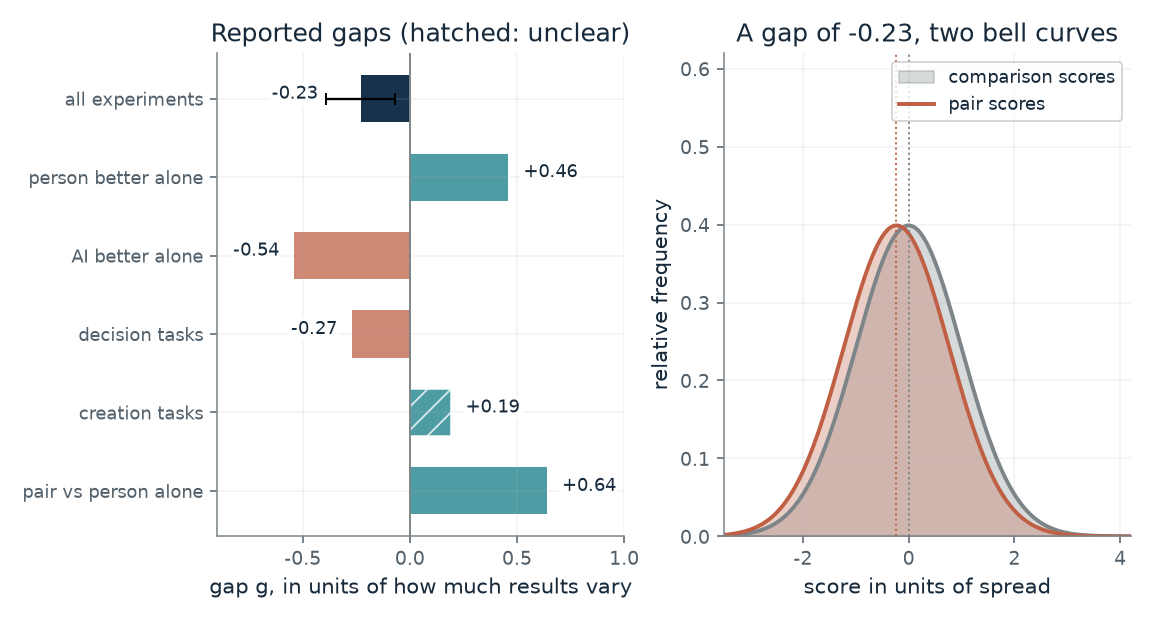

- **Gap g:** -0.23
- **Direction:** small, behind
- **Interval printed in the chapter:** -0.39 to -0.07
- **Pair beats comparison, normal reading:** 0.435

All experiments, pair against the better member alone: g = -0.23. If both sets of scores were bell-shaped with equal spread, a random pair score would beat a random comparison score about 44 percent of the time; this reading is the companion's, not the review's.

Chance of beating = Phi(g / sqrt 2) = Phi(-0.23 / 1.414) = 0.435. The review's 95 percent interval is given for the all-experiments gap only: -0.39 to -0.07.

In [2]:
figure, values, explanation = gap_picture(**{'view': 'all'})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='Did pairs beat their better member on average?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Which gap = ai_better: When the AI alone was better, the pair lost by 0.54. When the person alone was better, the pair gained by 0.46. The overall minus 0.23 hides that split, and the authors offer a hypothesis, not a test, for why people who beat the AI gain.

**Takeaway:** On average the pair beat the person alone (plus 0.64) but trailed its better member (minus 0.23); the gap changed sign with who was better alone.

**Why it matters:** A pair can improve on the person and still do worse than the machine. The yardstick has to be the better solo score, and the answer depends on the task and on who leads.

**In brains and behavior:** The person in these experiments is a human participant making a decision or creating content. The review says nothing about how a mind does either.

**In machines:** The AI is whatever system each experiment used. The review pools many tasks, so its averages describe the studies collected, not any one system.

**Where it applies:** The review covers the studies the authors collected, mostly decision tasks, published from 2020 to June 2023, when chat models were rare in trials. In over 95 percent of its systems the person made the final decision after advice. The bell-curve reading assumes equal spread and normal shape, which the review does not claim.

**Check your understanding:** The pair gained 0.64 against the person alone yet lost 0.23 against the better member. How can both be true?

<details><summary>Show the answer</summary>

The better member is the person in some experiments and the AI in others. Against the person alone the pair gains, but where the AI was better the pair falls behind it, and that pulls the average against the better member below zero.

</details>

*Source: Chapter 25, On average pairs trailed their better member by 0.23, except when the person led. Reported values quoted in the chapter from Vaccaro, Almaatouq and Malone (2024), a review of 106 experiments: g of minus 0.23 for the pair against the better member (95 percent interval minus 0.39 to minus 0.07), plus 0.46 when the person was better alone, minus 0.54 when the AI was, minus 0.27 for decision tasks, plus 0.19 for creation tasks (not clearly above zero on its own), plus 0.64 against the person alone. The bell-curve picture and the probability it gives are this companion's own reading. No simulation.*

## C25-D02: When should a case go to the person?

A model is right 0.95 of the time on clear cases and 0.60 on hard ones. A counselor is right 0.90 and 0.70, and asking costs 0.05. Which cases should go to the counselor, and does the system beat the better solo score?

For each case type compare the person's chance of being right, less the cost of asking, with the machine's chance. If the person wins, route those cases to the person. The system's accuracy is the share-weighted success of whoever answers, and its net score takes off the asking charge.

$$
h(x)-c>q(x)
$$

**Symbols:** x: the case (here its type, clear or hard); h(x): the person's expected success on that case; q(x): the machine's expected success on that case; c: the cost of consulting the person, on the same scale

**Predict before looking:** Predict how high the asking cost can get before the hard cases stop going to the counselor, when the counselor is right 0.70 of the time on them.

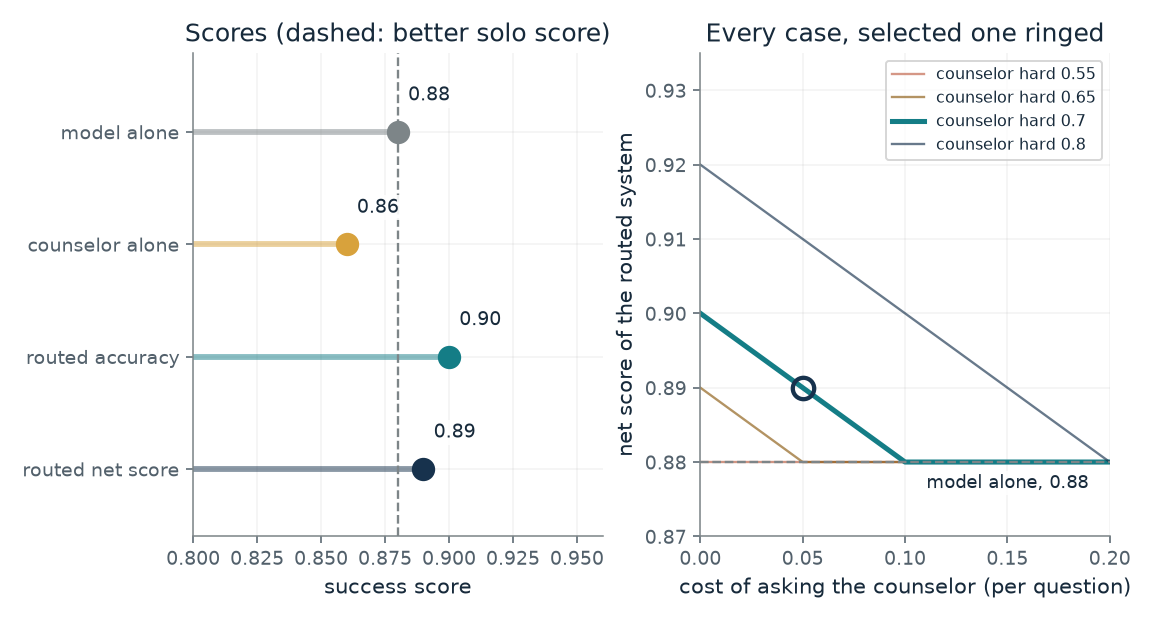

- **Sent to the counselor:** hard cases
- **Routed accuracy:** 0.9
- **Net score after asking charge:** 0.89
- **Beats the better solo score?:** yes, better solo is 0.88

With an asking cost of 0.05 and the counselor right on hard cases 0.7 of the time, the system sends hard cases to the counselor. Accuracy is 0.9, net score 0.89, against a better solo score of 0.88.

Model alone: 0.8 x 0.95 + 0.2 x 0.60 = 0.88. Counselor alone: 0.8 x 0.90 + 0.2 x 0.7 = 0.86. Rule h - c > q: clear 0.85 vs 0.95; hard 0.65 vs 0.60. Net = accuracy - 0.05 x share routed (0.2).

In [3]:
figure, values, explanation = routing_picture(**{'cost': 0.05, 'counselor_hard': 0.7})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='When should a case go to the person?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Cost of asking, per question = 0.05, Counselor's success on hard cases = 0.7: Clear cases stay with the model (0.90 minus 0.05 is 0.85, short of 0.95). Hard cases go to the counselor (0.65 beats 0.60). Accuracy rises from 0.88 to 0.90, net score is 0.89, and the counselor alone scores 0.86, so the routed system beats the better solo score, 0.88.

**Takeaway:** Routing beat both solo scores in the constructed case, but only while asking costs under 0.10 and the counselor is clearly better on hard cases.

**Why it matters:** A routing design needs the case types and each partner's success rates before the answer is known. The gain is real in the example and disappears when any of those inputs is wrong.

**In brains and behavior:** The counselor stands for a person with judgment on hard cases. Nothing here measures any person.

**In machines:** The model is a specification: its success rates are stated inputs, not outputs of a real system.

**Where it applies:** Case types are recognized in advance, both success rates are known for each type, and the cost is on the same scale as success. All three must be estimated under the conditions of use; mistakes in any of them can erase the gain. A tie keeps the case with the machine.

**Check your understanding:** Raise the cost to 0.10 with the counselor at 0.70 on hard cases. What happens to the hard cases and to the net score?

<details><summary>Show the answer</summary>

0.70 minus 0.10 equals 0.60, which does not beat the model's 0.60 (a tie keeps the case with the machine). Nothing is routed, and the net score returns to the model alone, 0.88.

</details>

*Source: Chapter 25, Two hand-off methods were tested only with stand-ins for people. Book formula and constructed example. The cost-of-asking form of the rule is the book's statement, not the papers'. All numbers are made up for illustration (four clear cases in five; model 0.95 and 0.60; counselor 0.90 and 0.70; cost 0.05). The other costs and hard-case accuracies are this companion's variations. Neither hand-off paper put a person in the loop.*

## C25-D03: How often must a person win an override for it to pay?

A counselor and a rule disagree on 150 of 1,000 students. The counselor is right on 60 of them. If the counselor overrides every disagreement, what happens to accuracy?

On agreements the person and the rule score the same, so the overall change comes from the disagreements alone. If the person overrides all of them, each win gains one case and each loss costs one. The net is wins minus losses, divided by the number of students.

$$
P(\text{person right}\mid\text{disagreement})>\tfrac12
$$

**Symbols:** P: a probability; |: 'given': the chance the person is right, given that the two disagree; 1/2: the break-even share when each kind of error costs the same

**Predict before looking:** Predict the change in accuracy, in points, if the person wins only 40 percent of 150 disagreements out of 1,000 students.

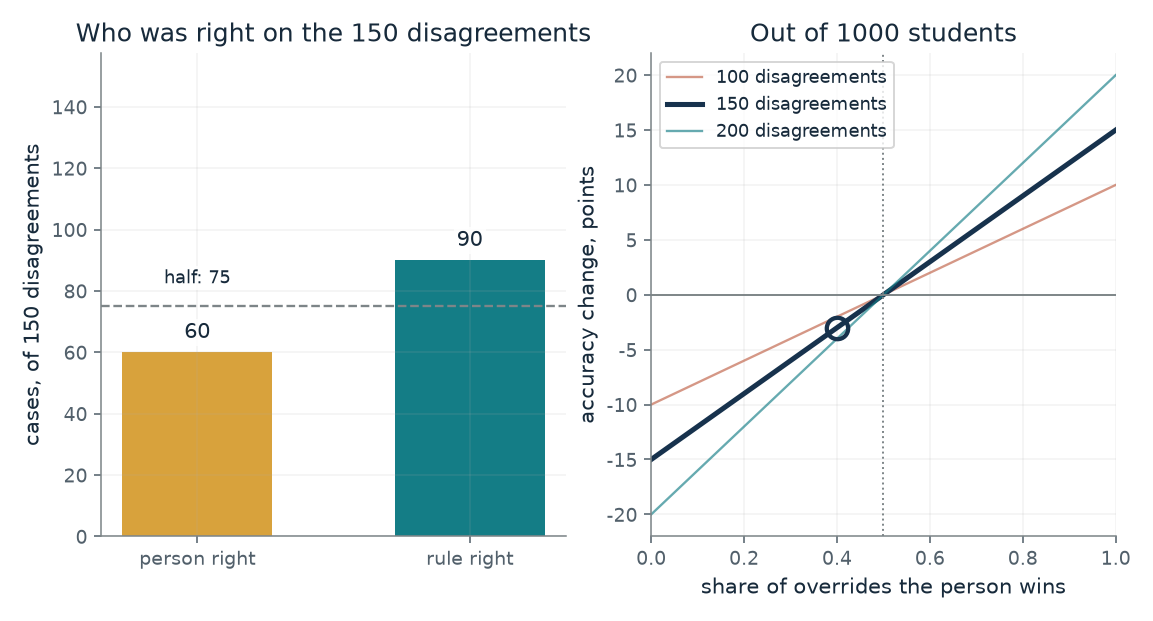

- **Overrides won:** 60 of 150
- **Net cases:** -30
- **Accuracy change:** -3.0 points
- **Verdict:** overrides cost accuracy

The person overrides all 150 disagreements and is right on 60 (40 percent), so overrides cost accuracy: -30 cases, -3.0 points of accuracy.

Net cases = 60 - 90 = -30. Accuracy change = -30 / 1000 = -0.030. An override pays only if the win share is above 1/2.

In [4]:
figure, values, explanation = override_picture(**{'disagreements': 150, 'win_rate': 0.4})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='How often must a person win an override for it to pay?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Disagreements out of 1,000 students = 150, Share of overrides the person wins = 0.4: The counselor is right on 60 of the 150 and the rule on 90, so the overrides lose 30 cases, three points of accuracy out of 1,000. At 50 percent they break even, and every disagreement won beyond half adds to accuracy.

**Takeaway:** Overrides cost accuracy whenever the person is right on fewer than half of the disagreements, and the cost grows with the number of disagreements.

**Why it matters:** Only disagreement cases can change the score, so the win rate on those cases is the whole question. Software could log each override and its outcome and show the person their own record.

**In brains and behavior:** The person is a counselor, clinician or other judge. Dawes, Faust and Meehl reported that the limited research on overrides showed more accuracy when clinicians relied on the rule.

**In machines:** The rule is a fixed formula that weighs the cues the same way every time.

**Where it applies:** A yes or no forecast with equal costs for each kind of error, at least one disagreement, and a person who overrides every disagreement. Where person and rule agree, their scores match. An override that sets the formula aside for a rare, checkable fact it cannot see, like Meehl's broken leg, is a different and easier case.

**Check your understanding:** With 200 disagreements and a 60 percent win share among 1,000 students, what is the change in accuracy?

<details><summary>Show the answer</summary>

The person is right on 120 and the rule on 80, a net of plus 40 cases, or plus 4 points. Above half, the overrides pay.

</details>

*Source: Chapter 25, Overrides likely lose, and showing the AI first nudged agreement up. Book formula and constructed example (1,000 students, 150 disagreements, the counselor right on 60 and the rule on 90). The other disagreement counts and win shares are this companion's variations. The chapter notes that Grove and Meehl inferred, and Dawes, Faust and Meehl reported directly, that overrides tended to lose; no data are used here.*

## C25-D04: Did doctors with a chat model beat the chat model alone?

Three trials gave doctors, or the public, a chat model and also scored the model alone. How big was the gain from the model, and how far did the people using it fall short of the model alone?

Each trial has an arm with the model and an arm without, and an arm where the model worked alone. The gain is the first difference and the gap is the second. Putting them in one stack shows how much of the distance to the model's score the people closed.

$$
\text{gain}=\bar x_{\text{pair}}-\bar x_{\text{no model}},\qquad \text{gap}=\bar x_{\text{model alone}}-\bar x_{\text{pair}}
$$

**Symbols:** gain: points the model added for the people using it, as reported; gap: points by which the model alone scored above the people using it

**Predict before looking:** Before switching trials, predict whether the doctors using the model reached the model's own score in any of the three doctor trials.

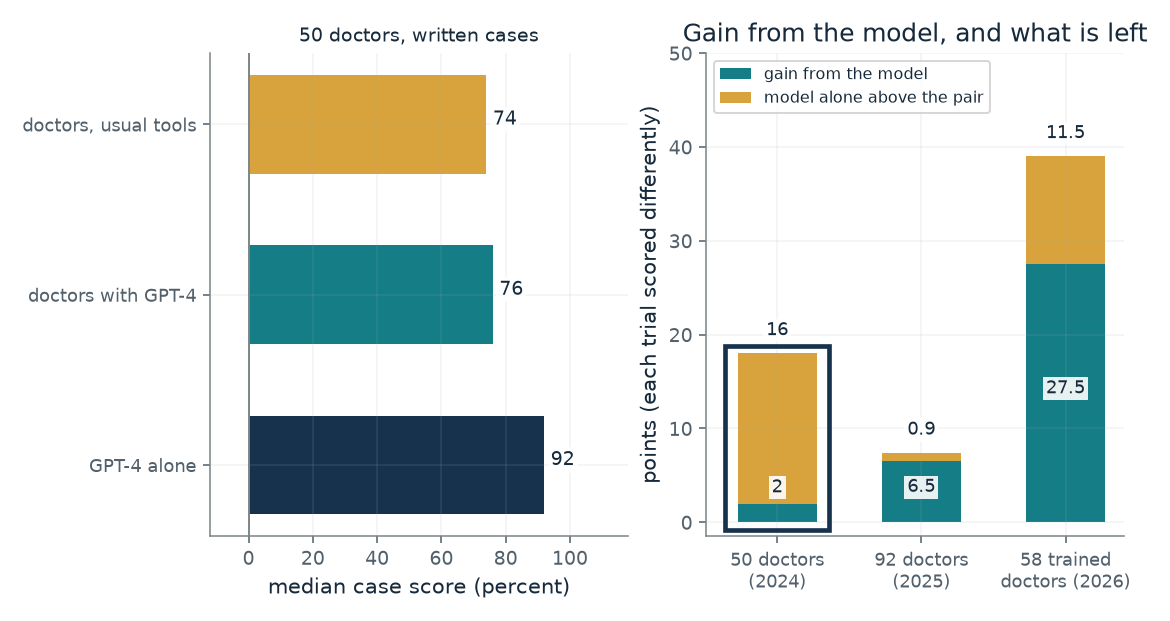

- **Gain from the model (points):** 2
- **Model alone above the pair (points):** about 16
- **How that gap was obtained:** a reading of medians, not tested

50 doctors, written cases: the model added 2 points for the people using it, yet the model alone sat about 16 points above them. The trials are scored differently and cannot be pooled.

GPT-4 alone: three model-only runs. The paper did not test the pair against the model alone.

In [5]:
figure, values, explanation = trial_picture(**{'trial': 'goh24'})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='Did doctors with a chat model beat the chat model alone?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Which trial = qazi: In the trained-doctor trial the model added 27.5 points, yet the model alone still scored 11.5 points above the doctors working with it. The pair beat the model's median in 31.4 percent of cases.

**Takeaway:** In each trial the machine alone scored at or above the people using it (in the 92-doctor trial by about a point, too small to tell from zero), though the arms received different inputs and one comparison was not tested directly.

**Why it matters:** A pair can improve on the person and still do worse than the machine. This is the strongest reason the chapter asks for a test of the whole arrangement against each partner alone.

**In brains and behavior:** The people are doctors or members of the public, so the results are about how people use a chat model, not about neurons.

**In machines:** The chat models are the stronger solo member in these written-case tasks, as in the review's split by who was better alone.

**Where it applies:** The trials score different things, so the points are not comparable across them. The opening trial did not test the pair directly against the model alone, and the model-alone arms were exploratory in some trials. The public trial's models received the whole scenario while participants had to convey the details. Written cases, not patients. Nothing here is a clinical claim.

**Check your understanding:** In the 50-doctor trial, why is the 16-point gap not a tested result?

<details><summary>Show the answer</summary>

The paper reports no separate test of the pair against GPT-4 alone. The 16 points are the difference between two medians, 92 and 76, so they are a reading of the numbers.

</details>

*Source: Chapter 25, Doctors with a chat model scored at or below the chat model alone. Reported values quoted in the chapter and its source notes: Goh and colleagues 2024 (50 doctors: medians 74, 76 and 92), Goh and colleagues 2025 (92 doctors: plus 6.5; about one point from GPT-4 alone), Qazi and colleagues 2026 (58 trained doctors: 71.4 against 42.6, adjusted 27.5; model alone 11.5 above the pair), Bean and colleagues 2026 (1,298 members of the public: 94.9 against under 34.5). The model-alone score of 82.9 is derived by this companion from two reported numbers. No simulation.*

## C25-D05: How often did a fixed rule match or beat the professional?

In 136 studies that set a fixed rule against a trained professional, the rule did clearly better in 64, about equal in 64, and worse in 8. What does that say, and how does the headline change with how ties are counted?

The chapter's three counts partition 136 studies. Crediting the rule only for clear wins gives 64 of 136. Setting ties aside gives 64 of the 72 studies with a winner. Letting ties count for the rule gives 128 of 136.

$$
\text{share}=\frac{\text{studies credited to the rule}}{\text{studies counted}}
$$

**Symbols:** 64, 64, 8: studies where the rule was clearly better, about equal, and the professional was better; 136: all studies Grove and Meehl gathered

**Predict before looking:** Predict the share of studies in which the rule did at least as well as the professional.

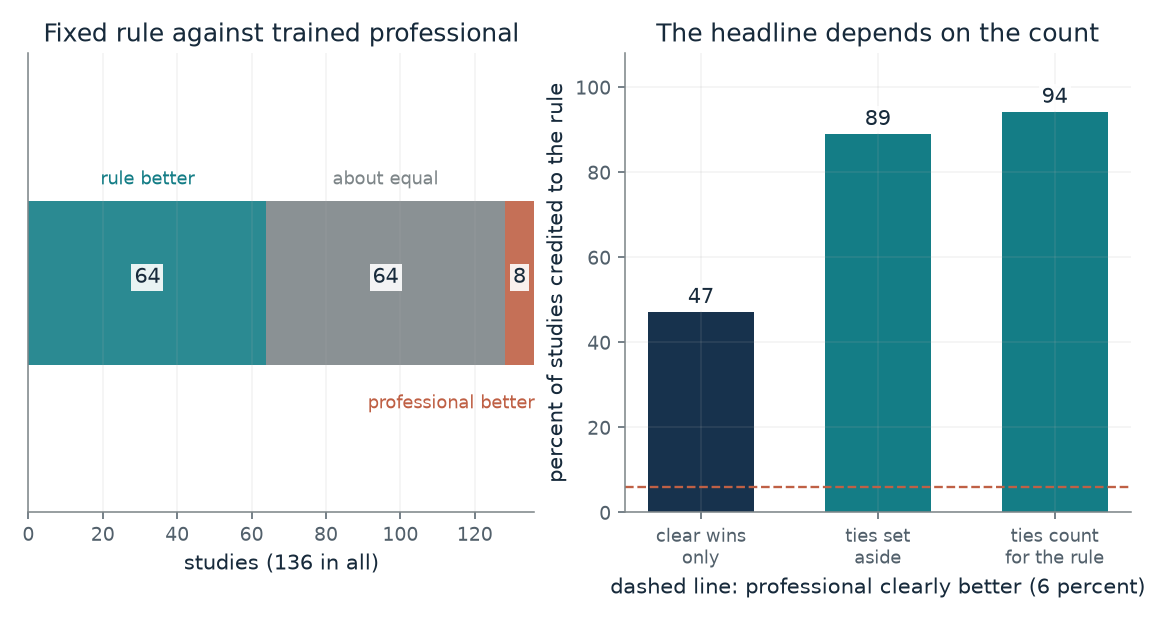

- **Studies:** 136
- **Credited to the rule:** 47 percent
- **Professional clearly better:** 8 of 136
- **Counting rule:** clear wins only

Of 136 studies, the rule did clearly better in 64, about equal in 64 and worse in 8. Counting clear wins only, the rule is credited in 47 percent. A count of studies cannot say why the rules won.

64 / 136 = 0.471.

In [6]:
figure, values, explanation = study_picture(**{'tie_rule': 'clear wins only'})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='How often did a fixed rule match or beat the professional?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At How to count ties = ties count for the rule: Counting ties for the rule, it matched or beat the professional in 128 of 136 studies, 94 percent. Counting only clear wins it is 47 percent. The professional clearly won only 8 times, about 6 percent, however ties are counted.

**Takeaway:** A fixed rule matched or beat the professional far more often than it lost, but the size of the headline depends on how the ties are counted.

**Why it matters:** The rule does not know anything the professional lacks. Its advantage is steadiness, and a tool could show a person the same cases twice and report how far the two ratings differ.

**In brains and behavior:** The professionals were trained clinicians and similar judges. The drift of a judge from case to case is inferred from the rule's success, not measured.

**In machines:** The rule is a fixed equation or table that weighs the cues the same way each time. It holds no new knowledge.

**Where it applies:** The studies are those the authors could find, so the count describes that collection, not every task. A count of studies cannot say why the rules won; steadier use of the cues and better weights both fit the facts.

**Check your understanding:** If you set ties aside, what share of the studies with a winner went to the rule?

<details><summary>Show the answer</summary>

64 of the 72 studies where one side won, which is 0.889, about 89 percent.

</details>

*Source: Chapter 25, A fixed rule often matched or beat the professional it replaced. Reported counts quoted in the chapter from Grove and Meehl (1996): 136 studies, 64 where the rule did clearly better (a gap about as large as 60 percent right against 50), 64 about equal, 8 where the professional won. The three ways of counting ties are this companion's own arithmetic. The chapter's source note says a later analysis counted slightly differently (63, 65 and 8).*

## C25-D06: Why did a copy of a psychologist do as well as the psychologist?

Clinical psychologists rated 861 patients from their questionnaire scores. An equation tuned to each psychologist's own ratings did slightly better on the recorded diagnosis. What do the correlations say?

Squaring a correlation gives the share of the criterion's variation that a straight-line relationship accounts for. For .28 that is about 8 percent and for .31 about 10 percent. Both are small, so none of the three predicts the diagnosis well.

$$
r^{2}=r\times r
$$

**Symbols:** r: the correlation with the recorded diagnosis: 1 is a perfect positive linear relationship, 0 is no linear relationship; r squared: the share of variation that a straight-line relationship accounts for (this companion's reading)

**Predict before looking:** Predict whether an equation with random weights does better or worse than the average judge.

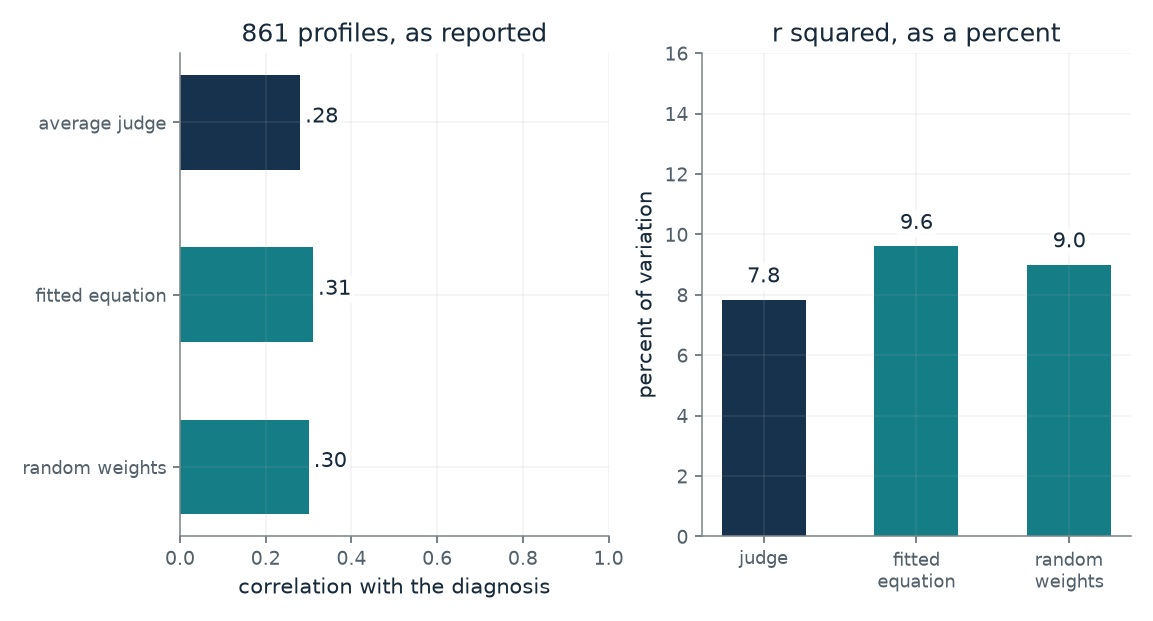

- **Correlation:** 0.28
- **Straight-line share of variation (companion's arithmetic):** 7.8 percent
- **Compared with:** the recorded diagnosis, neurotic or psychotic

For the average judge, the reported correlation with the recorded diagnosis is 0.28. The fitted equation (.31) edged out the average judge (.28), and equations with random weights scored .30, so steady use of the cues may matter as much as good weights.

r squared = 0.28 x 0.28 = 0.0784, about 7.8 percent. The chapter gives only the correlations.

In [7]:
figure, values, explanation = correlation_picture(**{'who': 'judge'})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='Why did a copy of a psychologist do as well as the psychologist?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Which scorer = random: Equations with random weights scored .30, above the average judge's .28 and close to the fitted equation's .31. The advantage here is steady use of the cues, not good weights; the chapter says a plausible reason is that the equation weighs the cues the same way every time.

**Takeaway:** Steady use of the cues did about as well as the professional's judgment, and random weights did about as well as the fitted ones.

**Why it matters:** A fixed rule gets credit for consistency. The design lesson is to collect the person's judgment under comparable conditions and keep a benchmark.

**In brains and behavior:** The judges were clinical psychologists reading questionnaire profiles. The correlation says how well their ratings tracked a diagnosis, not how they reasoned.

**In machines:** The fitted equation is a model of the judge's habits. The random-weight equation is a rule with no tuning at all.

**Where it applies:** The criterion was the recorded diagnosis, neurotic or psychotic, in one data set of 861 profiles. The equation held no new knowledge, only the psychologist's habits. No account reports a judge rating the same profile twice, so the drift is inferred, not measured.

**Check your understanding:** Why does the chapter not conclude that the equation held more knowledge than the judge?

<details><summary>Show the answer</summary>

The equation was tuned to the judge's own ratings from the same scores. It held only the judge's habits, so its small edge points to steadiness rather than new knowledge.

</details>

*Source: Chapter 25, A fixed rule often matched or beat the professional it replaced. Reported correlations quoted in the chapter and its source notes from Goldberg (1970) and Dawes (1979): the average judge .28, the average fitted equation .31, and equations with random weights .30. The r squared values are this companion's own arithmetic. Accounts differ on how many equations beat their judges, so no count is printed. No simulation.*

## Bring it to your own question

Ask what the person alone, the machine alone and the pair each score on comparable cases, what asking the person costs, and how many cases the two disagree on. Use the routing card to compare the partners case type by case type, and the override card to say whether the person wins more than half of the disagreements. Report the whole arrangement against each partner alone, and say which numbers were estimated under the conditions of use.

Use the `mmi-ch25-designing-joint-intelligence` skill to choose a relevant equation, work with your inputs, and interpret the result. The skill should explain the assumptions and distinguish an illustration from evidence about your particular situation.